# SeaTrace — Tower Bay Giant Kelp Analysis

This notebook contains the **clean Giant Kelp analysis only**, starting from the Tower Bay study polygon.  
The earlier TASSE current-extraction, package-debugging, DBF-testing, and failed zoom cells from the original notebook are intentionally excluded.

### Input
The following ESRI Shapefile components must be in the same working directory:

- `GiantKelp.shp`
- `GiantKelp.shx`
- `GiantKelp.dbf`
- `GiantKelp.prj`

The IMAS KelpWatch layer contains:

- `ID`
- `Year`
- `Zone`
- `Area_ha`
- `geometry`

### Analysis performed
1. Load and validate the IMAS Giant Kelp layer.
2. Define the Tower Bay study polygon.
3. Clip Giant Kelp detections to Tower Bay.
4. Recalculate clipped kelp area in hectares.
5. Summarise kelp area by year.
6. Summarise kelp area by year and IMAS zone.
7. Plot the 2016–2023 kelp-area trend.
8. Map all Tower Bay detections.
9. Map the latest available year.
10. Find the Giant Kelp polygons nearest to the Tower Bay reference point.

> **Interpretation:** This dataset represents remotely mapped Giant Kelp canopy in the Tower Bay region. It should not automatically be interpreted as cultivated farm biomass.

## Cell 1 — Load the IMAS Giant Kelp shapefile

This cell imports the required geospatial and plotting libraries, reads `GiantKelp.shp`, and checks that the coordinate system and expected attributes are present.

The shapefile is converted to `EPSG:4326` if necessary so that the Tower Bay longitude/latitude polygon can be used safely.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box, Point

# Load the IMAS Giant Kelp shapefile.
gdf_full = gpd.read_file("GiantKelp.shp")

# Ensure longitude/latitude coordinates are used for the spatial crop.
if gdf_full.crs is None:
    raise ValueError("The Giant Kelp shapefile has no CRS information.")

if gdf_full.crs.to_epsg() != 4326:
    gdf_full = gdf_full.to_crs("EPSG:4326")

required_columns = {"ID", "Year", "Zone", "Area_ha", "geometry"}
missing_columns = required_columns.difference(gdf_full.columns)

if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

print("CRS:", gdf_full.crs)
print("Dataset bounds:", gdf_full.total_bounds)
print("Number of Giant Kelp polygons:", len(gdf_full))
print("Years:", sorted(gdf_full["Year"].unique()))
print("\nColumns:")
print(gdf_full.columns.tolist())

CRS: EPSG:4326
Dataset bounds: [139.65937042 -43.86266924 150.11457455 -36.32954099]
Number of Giant Kelp polygons: 216189
Years: [np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

Columns:
['ID', 'Year', 'Zone', 'Area_ha', 'geometry']


## Cell 2 — Define the Tower Bay study polygon

This cell creates the SeaTrace Tower Bay region of interest (ROI) using the same approximate bounding box used in the working notebook:

- West: `147.00° E`
- East: `147.08° E`
- South: `43.43° S`
- North: `43.35° S`

This is a **study window**, not a claim that the rectangle is the legal IMAS lease boundary.

In [2]:
# Approximate SeaTrace Tower Bay study region.
LON_MIN = 147.00
LON_MAX = 147.08
LAT_MIN = -43.43
LAT_MAX = -43.35

tower_bbox = box(
    LON_MIN,
    LAT_MIN,
    LON_MAX,
    LAT_MAX,
)

tower_roi = gpd.GeoDataFrame(
    {"name": ["Tower Bay study region"]},
    geometry=[tower_bbox],
    crs="EPSG:4326",
)

print(tower_roi)

                     name                                           geometry
0  Tower Bay study region  POLYGON ((147.08 -43.43, 147.08 -43.35, 147 -4...


## Cell 3 — Clip Giant Kelp detections to Tower Bay

This cell spatially clips the full IMAS Giant Kelp dataset to the Tower Bay polygon.

Only kelp geometries that intersect the Tower Bay study region are retained. Because clipping can cut a polygon at the ROI boundary, the original `Area_ha` field is not used as the final Tower Bay area.

In [3]:
tower_kelp = gpd.clip(gdf_full, tower_roi).copy()

print("Giant Kelp polygons intersecting Tower Bay:", len(tower_kelp))

if tower_kelp.empty:
    raise ValueError("No Giant Kelp polygons were found inside the Tower Bay study region.")

print("\nYears represented:")
print(sorted(tower_kelp["Year"].unique()))

print("\nSample:")
print(tower_kelp.head())

Giant Kelp polygons intersecting Tower Bay: 956

Years represented:
[np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

Sample:
            ID  Year                                       Zone   Area_ha  \
171984  171985  2022  Near-Coast & Estuary/Embayment vegetation  0.005880   
203585  203586  2023  Near-Coast & Estuary/Embayment vegetation  0.000653   
63675    63676  2018  Near-Coast & Estuary/Embayment vegetation  0.001307   
203573  203574  2023  Near-Coast & Estuary/Embayment vegetation  0.001307   
143578  143579  2021  Near-Coast & Estuary/Embayment vegetation  0.003267   

                                                 geometry  
171984  POLYGON ((147.02439 -43.42991, 147.02441 -43.4...  
203585  POLYGON ((147.02385 -43.42924, 147.02385 -43.4...  
63675   POLYGON ((147.02355 -43.42908, 147.02358 -43.4...  
203573  POLYGON ((147.02355 -43.42908, 147.02358 -43.4...  
143578  POLYGON ((147.02355 -43

## Cell 4 — Recalculate kelp area after clipping

Area calculations should not be performed directly in `EPSG:4326` because its units are degrees.

This cell projects the clipped polygons to **GDA2020 / MGA Zone 55 (`EPSG:7855`)**, calculates the actual clipped polygon area in square metres, and converts it to hectares.

`Tower_area_ha` is therefore the area that actually falls inside the Tower Bay ROI.

In [4]:
tower_kelp_m = tower_kelp.to_crs("EPSG:7855").copy()

tower_kelp_m["Tower_area_m2"] = tower_kelp_m.geometry.area
tower_kelp_m["Tower_area_ha"] = tower_kelp_m["Tower_area_m2"] / 10_000

print(
    tower_kelp_m[
        ["ID", "Year", "Zone", "Area_ha", "Tower_area_ha"]
    ].head()
)

print(
    "\nTotal mapped kelp area across all year-records inside the ROI:",
    round(tower_kelp_m["Tower_area_ha"].sum(), 4),
    "ha",
)

            ID  Year                                       Zone   Area_ha  \
171984  171985  2022  Near-Coast & Estuary/Embayment vegetation  0.005880   
203585  203586  2023  Near-Coast & Estuary/Embayment vegetation  0.000653   
63675    63676  2018  Near-Coast & Estuary/Embayment vegetation  0.001307   
203573  203574  2023  Near-Coast & Estuary/Embayment vegetation  0.001307   
143578  143579  2021  Near-Coast & Estuary/Embayment vegetation  0.003267   

        Tower_area_ha  
171984       0.005875  
203585       0.000653  
63675        0.001306  
203573       0.001306  
143578       0.003264  

Total mapped kelp area across all year-records inside the ROI: 6.3135 ha


## Cell 5 — Calculate Giant Kelp area by year

This cell groups the clipped polygons by `Year` and sums the recalculated `Tower_area_ha`.

The output gives the remotely mapped Giant Kelp canopy area in the Tower Bay study region for each available year from 2016 to 2023.

In [5]:
yearly_area = (
    tower_kelp_m
    .groupby("Year", as_index=False)["Tower_area_ha"]
    .sum()
    .sort_values("Year")
)

yearly_area["Tower_area_ha"] = yearly_area["Tower_area_ha"].round(4)

print(yearly_area.to_string(index=False))

 Year  Tower_area_ha
 2016         0.1079
 2017         0.8444
 2018         0.6100
 2019         0.2103
 2020         0.5995
 2021         1.5639
 2022         0.5688
 2023         1.8088


## Cell 6 — Count mapped kelp polygons by year

Area and feature count describe different aspects of the dataset.

This cell counts how many separate Giant Kelp geometries occur in the Tower Bay ROI for each year. A larger number of polygons does not necessarily mean a larger total canopy area because polygon sizes vary.

In [6]:
yearly_count = (
    tower_kelp
    .groupby("Year")
    .size()
    .reset_index(name="Polygon_count")
    .sort_values("Year")
)

print(yearly_count.to_string(index=False))

 Year  Polygon_count
 2016             17
 2017            138
 2018             88
 2019             60
 2020             87
 2021            174
 2022            149
 2023            243


## Cell 7 — Summarise Giant Kelp area by year and IMAS zone

The IMAS layer contains a `Zone` attribute. This cell separates the Tower Bay area by both year and zone so that near-coast / estuary / embayment detections can be distinguished from other classification zones present in the dataset.

In [7]:
year_zone_area = (
    tower_kelp_m
    .groupby(["Year", "Zone"], as_index=False)["Tower_area_ha"]
    .sum()
    .sort_values(["Year", "Zone"])
)

year_zone_area["Tower_area_ha"] = year_zone_area["Tower_area_ha"].round(4)

print(year_zone_area.to_string(index=False))

 Year                                      Zone  Tower_area_ha
 2016 Near-Coast & Estuary/Embayment vegetation         0.1079
 2017 Near-Coast & Estuary/Embayment vegetation         0.7582
 2017 Open Water vegetation - Giant Kelp likely         0.0862
 2018 Near-Coast & Estuary/Embayment vegetation         0.6067
 2018 Open Water vegetation - Giant Kelp likely         0.0033
 2019 Near-Coast & Estuary/Embayment vegetation         0.2103
 2020 Near-Coast & Estuary/Embayment vegetation         0.5695
 2020 Open Water vegetation - Giant Kelp likely         0.0300
 2021 Near-Coast & Estuary/Embayment vegetation         0.9815
 2021 Open Water vegetation - Giant Kelp likely         0.5824
 2022 Near-Coast & Estuary/Embayment vegetation         0.5492
 2022 Open Water vegetation - Giant Kelp likely         0.0196
 2023 Near-Coast & Estuary/Embayment vegetation         1.6475
 2023 Open Water vegetation - Giant Kelp likely         0.1613


## Cell 8 — Plot the 2016–2023 Giant Kelp area trend

This cell visualises how the mapped Giant Kelp canopy area changes through time inside the Tower Bay study region.

The graph represents **remote-sensing canopy extent**, not measured farm harvest or cultivated biomass.

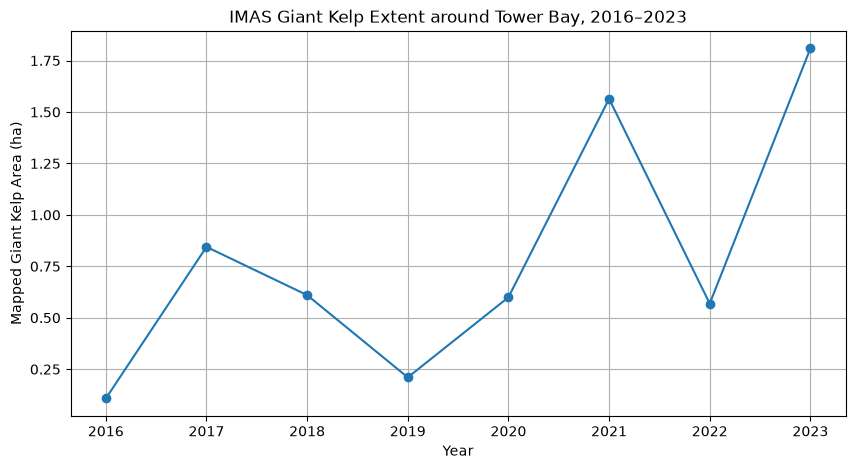

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    yearly_area["Year"],
    yearly_area["Tower_area_ha"],
    marker="o",
)

ax.set_xlabel("Year")
ax.set_ylabel("Mapped Giant Kelp Area (ha)")
ax.set_title("IMAS Giant Kelp Extent around Tower Bay, 2016–2023")
ax.grid(True)

plt.show()

## Cell 9 — Map all Giant Kelp detections inside the Tower Bay ROI

This cell draws the Tower Bay study boundary and all Giant Kelp geometries found within it.

Because individual kelp polygons can be very small, the map is automatically fitted to the ROI rather than the full southern-Australia dataset.

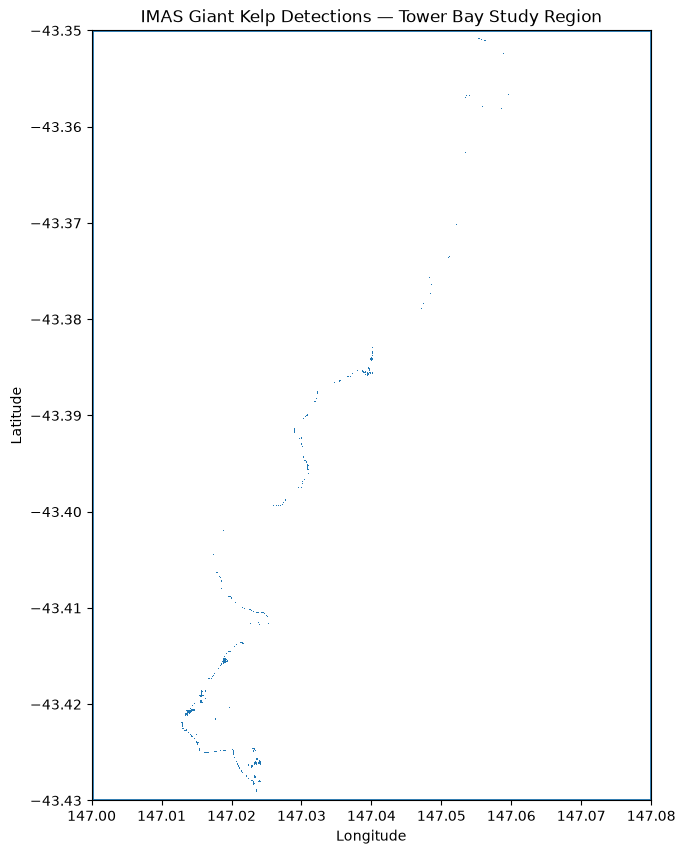

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))

tower_kelp.plot(
    ax=ax,
    edgecolor="none",
)

tower_roi.boundary.plot(
    ax=ax,
    linewidth=2,
)

ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("IMAS Giant Kelp Detections — Tower Bay Study Region")

plt.show()

## Cell 10 — Map the latest available year

This cell identifies the latest year in the shapefile automatically and maps only that year's Giant Kelp detections inside Tower Bay.

Using `max()` avoids hard-coding 2023 if the shapefile is replaced later with a newer release.

Latest year: 2023
Polygons in 2023: 243


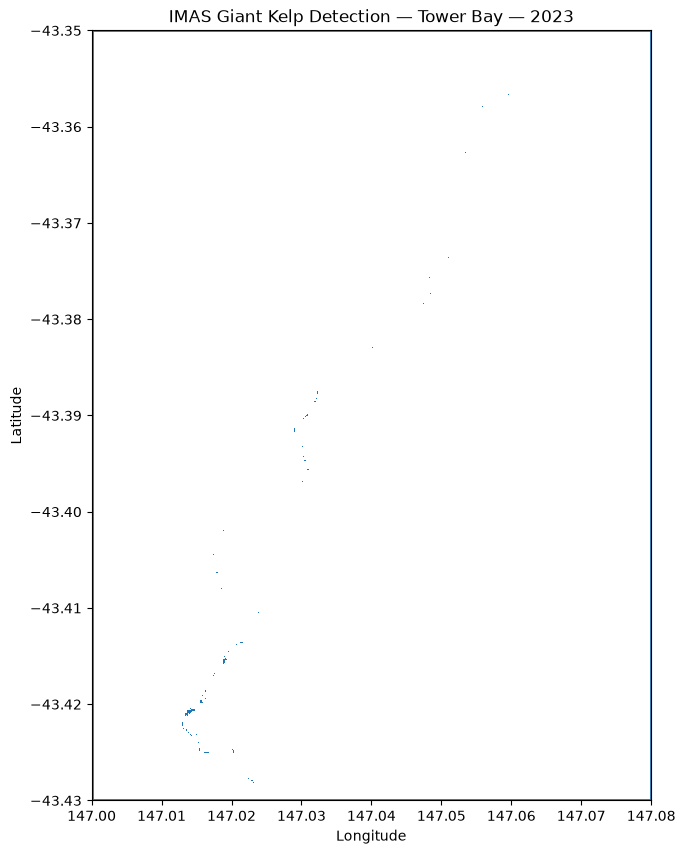

In [10]:
latest_year = int(tower_kelp["Year"].max())
kelp_latest = tower_kelp[tower_kelp["Year"] == latest_year]

print(f"Latest year: {latest_year}")
print(f"Polygons in {latest_year}: {len(kelp_latest)}")

fig, ax = plt.subplots(figsize=(10, 10))

kelp_latest.plot(
    ax=ax,
    edgecolor="none",
)

tower_roi.boundary.plot(
    ax=ax,
    linewidth=2,
)

ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"IMAS Giant Kelp Detection — Tower Bay — {latest_year}")

plt.show()

## Cell 11 — Automatically zoom to the detected kelp

The full Tower Bay rectangle can make small kelp polygons difficult to see.

This cell calculates the spatial bounds of the detected kelp and adds a small amount of padding so the plot automatically zooms to the actual mapped features. This avoids manually guessing longitude/latitude windows that may contain no polygons.

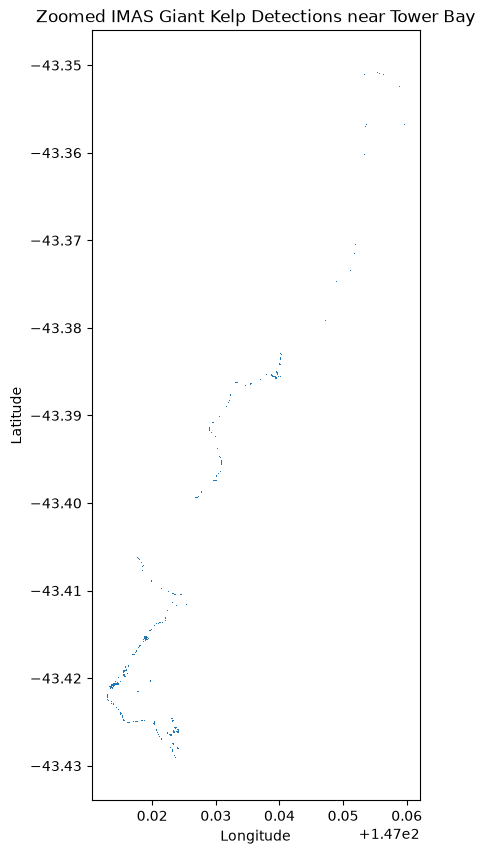

In [11]:
xmin, ymin, xmax, ymax = tower_kelp.total_bounds

x_range = xmax - xmin
y_range = ymax - ymin

padding_x = max(x_range * 0.05, 0.001)
padding_y = max(y_range * 0.05, 0.001)

fig, ax = plt.subplots(figsize=(10, 10))

tower_kelp.plot(
    ax=ax,
    edgecolor="none",
)

ax.set_xlim(xmin - padding_x, xmax + padding_x)
ax.set_ylim(ymin - padding_y, ymax + padding_y)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Zoomed IMAS Giant Kelp Detections near Tower Bay")

plt.show()

## Cell 12 — Find the Giant Kelp polygons nearest to the Tower Bay reference point

This cell uses the approximate Tower Bay reference point (`147.04° E, 43.39° S`) and calculates distance to every Giant Kelp polygon.

Distances are calculated in metres using `EPSG:7855`, then the 20 nearest detections are returned.

This is useful for checking whether mapped Giant Kelp occurs immediately around the SeaTrace case-study location or farther away.

In [12]:
tower_point = gpd.GeoDataFrame(
    {"name": ["Tower Bay reference point"]},
    geometry=[Point(147.04, -43.39)],
    crs="EPSG:4326",
)

kelp_m = gdf_full.to_crs("EPSG:7855").copy()
tower_point_m = tower_point.to_crs("EPSG:7855")

kelp_m["distance_m"] = kelp_m.geometry.distance(
    tower_point_m.geometry.iloc[0]
)

nearest = kelp_m.nsmallest(20, "distance_m").copy()

nearest_table = nearest[
    ["ID", "Year", "Zone", "Area_ha", "distance_m"]
].copy()

nearest_table["distance_m"] = nearest_table["distance_m"].round(1)

print(nearest_table.to_string(index=False))

    ID  Year                                      Zone  Area_ha  distance_m
142961  2021 Near-Coast & Estuary/Embayment vegetation 0.036614       462.7
118676  2020 Near-Coast & Estuary/Embayment vegetation 0.039229       464.7
 38895  2017 Near-Coast & Estuary/Embayment vegetation 0.023538       468.6
 38897  2017 Near-Coast & Estuary/Embayment vegetation 0.036614       471.9
 38899  2017 Near-Coast & Estuary/Embayment vegetation 0.026807       481.7
120249  2020 Near-Coast & Estuary/Embayment vegetation 0.023537       484.7
 63577  2018 Near-Coast & Estuary/Embayment vegetation 0.028768       491.4
 38894  2017 Near-Coast & Estuary/Embayment vegetation 0.021576       496.2
120250  2020 Near-Coast & Estuary/Embayment vegetation 0.050998       500.2
118675  2020 Near-Coast & Estuary/Embayment vegetation 0.018961       504.9
120251  2020 Near-Coast & Estuary/Embayment vegetation 0.000654       508.1
171915  2022 Near-Coast & Estuary/Embayment vegetation 0.001962       510.7
 63587  2018

## Cell 13 — Map the nearest Giant Kelp detections

The nearest polygons are converted back to `EPSG:4326` and plotted together with the Tower Bay reference point.

The map automatically fits the nearest detected polygons, which is more informative than plotting them against the full regional dataset.

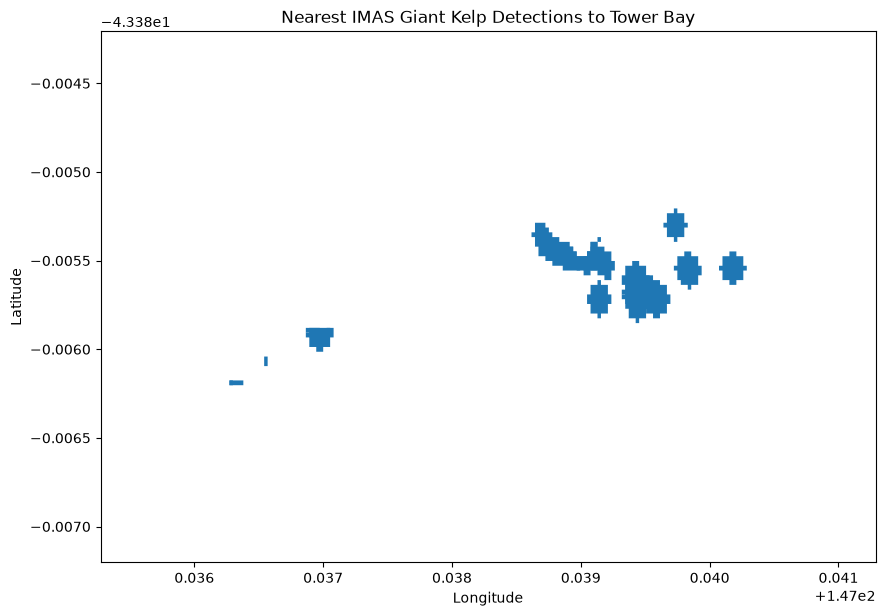

In [13]:
nearest_wgs = nearest.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 10))

nearest_wgs.plot(
    ax=ax,
    edgecolor="none",
)

tower_point.plot(
    ax=ax,
    marker="x",
    markersize=100,
)

xmin, ymin, xmax, ymax = nearest_wgs.total_bounds
padding_x = max((xmax - xmin) * 0.10, 0.001)
padding_y = max((ymax - ymin) * 0.10, 0.001)

ax.set_xlim(xmin - padding_x, xmax + padding_x)
ax.set_ylim(ymin - padding_y, ymax + padding_y)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Nearest IMAS Giant Kelp Detections to Tower Bay")

plt.show()

## Cell 14 — Export the clean Tower Bay results

This optional final cell saves the derived data so they can be reused by SeaTrace without repeating the spatial processing.

Outputs:

- `tower_bay_giant_kelp_clipped.geojson` — clipped Giant Kelp geometries and attributes.
- `tower_bay_giant_kelp_yearly_area.csv` — yearly canopy area.
- `tower_bay_giant_kelp_year_zone_area.csv` — yearly canopy area by IMAS zone.
- `tower_bay_nearest_giant_kelp.csv` — 20 nearest mapped kelp polygons and their distance to the Tower Bay reference point.

In [14]:
tower_kelp.to_file(
    "tower_bay_giant_kelp_clipped.geojson",
    driver="GeoJSON",
)

yearly_area.to_csv(
    "tower_bay_giant_kelp_yearly_area.csv",
    index=False,
)

year_zone_area.to_csv(
    "tower_bay_giant_kelp_year_zone_area.csv",
    index=False,
)

nearest_table.to_csv(
    "tower_bay_nearest_giant_kelp.csv",
    index=False,
)

print("Export complete.")

Export complete.
